<a href="https://colab.research.google.com/github/piyush2500/Lab_work-Machine-learning/blob/main/K_means_ca2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score




import pandas as pd
from google.colab import files
import io


uploaded = files.upload()

file_name = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[file_name]),
                 sep=None, engine="python")

print("Dataset shape:", df.shape)
display(df.head())

print("\nMissing values (top columns):")
display(df.isna().sum().sort_values(ascending=False).head(10))


Saving marketing_campaign.csv to marketing_campaign (1).csv
Dataset shape: (2240, 29)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0



Missing values (top columns):


,0
Income,24
ID,0
Year_Birth,0
Education,0
Marital_Status,0
Kidhome,0
Teenhome,0
Dt_Customer,0
Recency,0
MntWines,0


In [2]:
df['Dt_Customer'] = pd.to_datetime(
    df['Dt_Customer'], dayfirst=True, errors='coerce'
)

df['Customer_Tenure'] = (
    df['Dt_Customer'].max() - df['Dt_Customer']
).dt.days


df = df.drop(columns=[
    'ID', 'Dt_Customer', 'Z_CostContact',
    'Z_Revenue', 'Response'
])


X = df.select_dtypes(include=np.number)
X = X.loc[:, X.nunique(dropna=True) > 1]


X = pd.DataFrame(
    SimpleImputer(strategy='median').fit_transform(X),
    columns=X.columns
)

print("Features used:", X.shape[1])
print(X.head())

Features used: 23
   Year_Birth   Income  Kidhome  Teenhome  Recency  MntWines  MntFruits  \
0      1957.0  58138.0      0.0       0.0     58.0     635.0       88.0   
1      1954.0  46344.0      1.0       1.0     38.0      11.0        1.0   
2      1965.0  71613.0      0.0       0.0     26.0     426.0       49.0   
3      1984.0  26646.0      1.0       0.0     26.0      11.0        4.0   
4      1981.0  58293.0      1.0       0.0     94.0     173.0       43.0   

   MntMeatProducts  MntFishProducts  MntSweetProducts  ...  \
0            546.0            172.0              88.0  ...   
1              6.0              2.0               1.0  ...   
2            127.0            111.0              21.0  ...   
3             20.0             10.0               3.0  ...   
4            118.0             46.0              27.0  ...   

   NumCatalogPurchases  NumStorePurchases  NumWebVisitsMonth  AcceptedCmp3  \
0                 10.0                4.0                7.0           0.0   
1 

In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

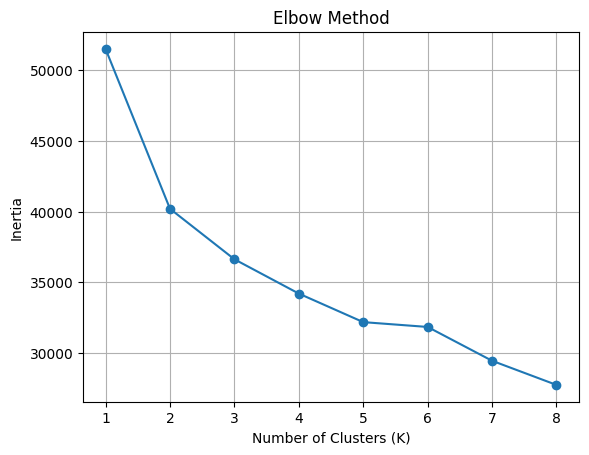

In [4]:
inertias = []
for k in range(1, 9):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    inertias.append(kmeans.inertia_)

# Plot the Elbow graph
plt.plot(range(1, 9), inertias, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.xticks(range(1, 9))
plt.grid(True)
plt.show()

In [5]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Fit the model and assign cluster labels
df['Cluster'] = kmeans.fit_predict(X_scaled)

# Display customer clusters
print(df[['Cluster']].head(10))

# Count customers in each cluster
print(df['Cluster'].value_counts().sort_index())

   Cluster
0        0
1        1
2        2
3        1
4        1
5        2
6        2
7        1
8        1
9        1
Cluster
0     548
1    1053
2     639
Name: count, dtype: int64


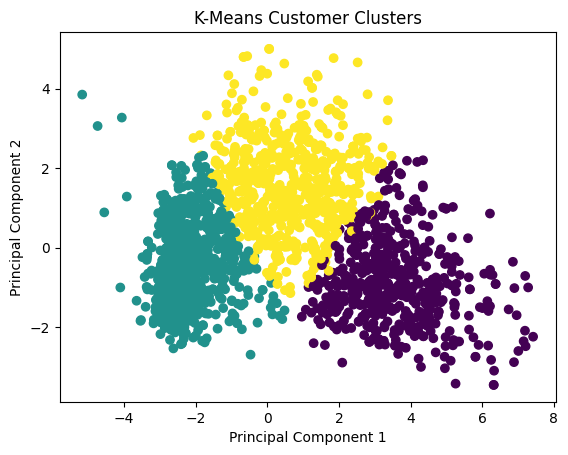

In [6]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=df['Cluster'],
    cmap='viridis'
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('K-Means Customer Clusters')
plt.show()